# Eight Gaussians OFM spike diagnostics

Run from the top to train or resume the diagnostic experiment. A spike is a batch whose `true_loss` reaches 100× the median of the previous 100 batches (at least 20 available). The notebook captures the batch before Adam, performs the usual update, saves the checkpoint, and pauses by default. Set `STOP_ON_SPIKE = False` to continue through subsequent spikes.

In the supplied profile, iteration 18,725 reached 33,702.26 against a preceding median of 32.33 (1,042×). The inverse reached all 10 outer steps and its maximum residual norm was 21.04. The archived profile contains scalar summaries and its checkpoint is at iteration 30,000, so this version captures attribution on a fresh run.

[Proposition 2, Eq. (18)](https://arxiv.org/html/2403.13117#S3.SS4) writes the OFM objective as squared inverse displacement divided by time squared. This repository logs the mean of `v²` summed over coordinates, where `v = 2*(X0 - Z0)/(t + 1e-5)`. Its inverse-Hessian vector and potential gradient form the training proxy in Proposition 1.

For each spike, `spikes/iter_*/summary.csv` compares the capped loss with a tighter inverse on the **same pre-update model and batch**. `components.csv` shows the signed increase by coordinate and by time bin against the median baseline batch or batches, plus how much each contribution changes after refinement. Each grouping independently sums to the total increase, up to roundoff. `samples.csv` ranks the original samples by their contribution to the batch mean and records displacement, time weight, inverse residual, and the proxy factors. `capture.pt` stores the exact batch and pre-update weights. When loading these weights into a new ICNN2CPF, pass `actnorm_initialized=True`. The reference solve reports an uncertainty interval based on its residual and the strong convexity bound from Eq. (17).

In [1]:
# parameters
DEVICE='mps'
MODEL = 'v2cpf'
INV_MAX_ITER = 10  # cap on outer L-BFGS steps of the inner solve

In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import numpy as np
import torch
import torch.distributions as TD
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import clear_output
import random
import time

import sys, os
from pathlib import Path

notebook_dir = Path.cwd()
if (notebook_dir / 'ofm_notebooks').is_dir():
    notebook_dir = notebook_dir / 'ofm_notebooks'
sys.path.append(str(notebook_dir.parent))

# icnns
from ofmsrc.icnn import (
    ICNNCPF,
    ICNN2CPF,
    ICNN3CPF,
    LseICNNCPF,
    ResICNN2CPF,
    DenseICNN2CPF
)
from ofmsrc.icnn import (
    LinActnormICNN,
    DenseICNN
)

from ofmsrc.model_tools import (
    id_pretrain_model,
    ofm_forward,
    ofm_loss
)
from ofmsrc.model_tools import (
    TorchoptimInvParams,
    TorchlbfgsInvParams,
    BruteforceIHVParams
)

from ofmsrc.inverse import ofm_inverse
from ofmsrc.ihv import ofm_ihv
from ofmsrc.ood import OOD

# dgm_utils
from ofmsrc.dgm_utils import visualize_2d_samples_groups, visualize_2d_map
from ofmsrc.tools import freeze, unfreeze, EMA

# spiral dataset etc.
from ofmsrc.distributions import Sampler, StandardNormalSampler

In [4]:
def seed_everything(seed=42):
    np.random.seed(seed)
    torch.random.manual_seed(seed)
    random.seed(seed)

### Source and Target distributions

/var/folders/fc/yhgfsqg501z7dxwxb4jbvpwr0000gn/T/ipykernel_29386/2534182524.py:34: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return torch.tensor(


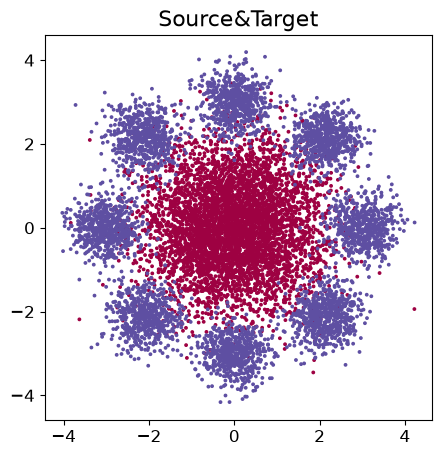

In [5]:
class Mix8GaussiansSampler(Sampler):
    def __init__(
        self, with_central=False, std=1, r=12, dim=2, device='cuda'
    ):
        super().__init__(
            device=device
        )
        assert dim == 2
        self.dim = 2
        self.std, self.r = std, r
        
        self.with_central = with_central
        centers = [
            (1, 0), (-1, 0), (0, 1), (0, -1),
            (1. / np.sqrt(2), 1. / np.sqrt(2)),
            (1. / np.sqrt(2), -1. / np.sqrt(2)),
            (-1. / np.sqrt(2), 1. / np.sqrt(2)),
            (-1. / np.sqrt(2), -1. / np.sqrt(2))
        ]
        if self.with_central:
            centers.append((0, 0))
        self.centers = torch.tensor(
            centers, device=self.device
        )
        
    def sample(self, batch_size=10):
        batch = torch.randn(
            batch_size, self.dim,
            device=self.device
        )
        indices = random.choices(range(len(self.centers)), k=batch_size)
        batch *= self.std
        batch += self.r * self.centers[indices, :]
        return torch.tensor(
            batch, device=self.device
        )

seed_everything()

mix8gau_sampler = Mix8GaussiansSampler(device='cpu', r=3, std=0.4)
standardnormal_sampler = StandardNormalSampler(device='cpu')

source_sampler = standardnormal_sampler
target_sampler = mix8gau_sampler

visualize_2d_samples_groups([
    source_sampler.sample(5024).cpu().numpy(), 
    target_sampler.sample(5024).cpu().numpy()], 'Source&Target', s=3)

### Model

In [6]:
seed_everything()

sampler = TD.Normal(
    torch.tensor([0., 0.]).to(DEVICE), 
    torch.tensor([4., 4.]).to(DEVICE))

def get_model(name):
    assert name in [
        'v2cpf'
    ]
    print(f"Used model: {name}")
    model = ICNN2CPF(dim=2, dimh=1024, num_hidden_layers=2, batch_size=1024).to(DEVICE)
    id_pretrain_model(model, sampler, n_max_iterations=200, lr=1e-2)
    return model


In [7]:
model = get_model(MODEL).to(DEVICE)
optim = torch.optim.Adam(model.parameters(), lr=1e-2)

100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████| 200/200 [00:01<00:00, 124.84it/s]

Loss: 0.31395775079727173


### Output directory

In [8]:
EXP_DIR = notebook_dir / f'gau_{MODEL}_cap{INV_MAX_ITER}_spike'
EXP_DIR.mkdir(exist_ok=True)
SPIKE_DIR = EXP_DIR / 'spikes'

samples_path = EXP_DIR / 'samples.png'
curr_model_path = EXP_DIR / 'model.pth'
loss_path = EXP_DIR / 'loss.png'

### Fitting eight gaussians

In [9]:
MAX_ITER = 30000  # total target; raise it and re-run to resume from the checkpoint
CKPT_EVERY = 500
BATCH_SIZE = 1024
INV_TOLERANCE = 0.01
LOSS_EPS = 1e-5  # matches ofm_loss
SPIKE_FACTOR = 100.0
BASELINE_WINDOW = 100
BASELINE_MIN_HISTORY = 20
STOP_ON_SPIKE = True  # resume from the saved checkpoint to capture later spikes


In [10]:
ema = EMA(0, betas=[0.999, 0.99])

In [11]:
import pandas as pd
from copy import deepcopy

CKPT_PATH = os.path.join(EXP_DIR, 'ckpt.pt')
PROFILE_CSV = os.path.join(EXP_DIR, 'profile.csv')
PROFILE_PNG = os.path.join(EXP_DIR, 'profile.png')

# per-iteration history (one entry per training iteration, times in seconds)
HIST_KEYS = ['loss', 'true_loss', 't_total', 't_inverse', 't_ihv', 'inv_steps', 'inv_norms_max', 't_min', 't_diag']
TIME_EDGES = np.array([0.001, 0.01, 0.1, 0.5, 0.9, 0.99])
TIME_KEYS = [
    f'true_loss_t_{lo:g}_to_{hi:g}'
    for lo, hi in zip([0, *TIME_EDGES], [*TIME_EDGES, 1])
]
AXIS_KEYS = ['true_loss_x', 'true_loss_y']
HIST_KEYS += AXIS_KEYS + TIME_KEYS + [
    'spike_baseline', 'spike_ratio', 'spike',
    'inverse_displacement_max', 'time_weight_max', 'true_loss_sample_max',
    'ihv_vector_norm_max', 'proxy_sample_abs_max', 't_spike_diag',
]
hist = {k: [] for k in HIST_KEYS}

# per-iteration convergence curves of the inner solve: one row per iteration, one column per outer L-BFGS step
# (column 0 = the initial point), NaN after the solve stopped
#   max_abs: max |g| over the batch (what tolerance_grad is compared against)
#   norm_max / norm_mean: max / mean over the batch of the per-sample l2 norm of g
#   n_iter / func_evals: cumulative inner L-BFGS iterations / closure evaluations
CONV_KEYS = ['max_abs', 'norm_max', 'norm_mean', 'n_iter', 'func_evals']
conv = {k: [] for k in CONV_KEYS}
CONV_NPZ = os.path.join(EXP_DIR, 'conv.npz')
CONV_PNG = os.path.join(EXP_DIR, 'conv.png')
start_iter = 0


def plot_profile(w=100):
    def smooth(a):
        a = np.asarray(a, dtype=float)
        if len(a) < w:
            return np.arange(len(a)), a
        return np.arange(w - 1, len(a)), np.convolve(a, np.ones(w) / w, mode='valid')

    fig, ax = plt.subplots(2, 2, figsize=(14, 8))
    ax[0, 0].semilogy(hist['true_loss'], lw=0.5); ax[0, 0].set_title('true_loss')
    for k in ['t_total', 't_inverse', 't_ihv']:
        x, y = smooth(hist[k])
        ax[0, 1].plot(x, 1e3 * y, label=k)
    ax[0, 1].set_title(f'time per iter, ms (moving avg {w})'); ax[0, 1].legend()
    x, y = smooth(hist['inv_steps'])
    ax[1, 0].plot(x, y); ax[1, 0].set_title(f'L-BFGS steps (moving avg {w})')
    ax[1, 1].semilogy(hist['inv_norms_max'], lw=0.5); ax[1, 1].set_title('inverse max grad norm')
    for a in ax.flat:
        a.set_xlabel('iteration')
    fig.tight_layout(); fig.savefig(PROFILE_PNG); plt.close(fig)


def plot_conv(tol=None):
    A = {k: np.asarray(v) for k, v in conv.items()}  # (N, INV_MAX_ITER + 1)
    N = len(A['max_abs'])

    def locf(a):  # solves that stopped early stay at their last residual
        a = a.copy()
        for j in range(1, a.shape[1]):
            m = np.isnan(a[:, j])
            a[m, j] = a[m, j - 1]
        return a

    starts = sorted({s for s in [0, 10000, 20000, N - 1000] if 0 <= s < N})
    windows = [(s, min(s + 1000, N)) for s in starts]
    steps = np.arange(A['max_abs'].shape[1])
    fig, ax = plt.subplots(2, 2, figsize=(14, 8))
    for lo, hi in windows:
        lab = f'iters {lo}-{hi}'
        L = {k: locf(A[k][lo:hi]) for k in ['max_abs', 'norm_max', 'norm_mean']}
        line, = ax[0, 0].semilogy(steps, np.median(L['max_abs'], 0), label=lab)
        ax[0, 0].semilogy(steps, np.quantile(L['max_abs'], 0.9, axis=0), '--', color=line.get_color())
        ax[0, 1].semilogy(steps, np.median(L['norm_max'], 0), color=line.get_color(), label=lab)
        ax[1, 0].semilogy(steps, np.median(L['norm_mean'], 0), color=line.get_color(), label=lab)
        ax[1, 1].plot(steps, (~np.isnan(A['max_abs'][lo:hi])).mean(0), color=line.get_color(), label=lab)
    if tol is not None:
        ax[0, 0].axhline(tol, color='k', ls=':', lw=1)
    ax[0, 0].set_title('max |g| over batch (stopping criterion): median, dashed = p90')
    ax[0, 1].set_title('max per-sample l2 norm of g: median')
    ax[1, 0].set_title('mean per-sample l2 norm of g: median')
    ax[1, 1].set_title('fraction of solves that performed >= k outer steps')
    for a in ax.flat:
        a.set_xlabel('outer L-BFGS step'); a.legend()
    fig.tight_layout(); fig.savefig(CONV_PNG); plt.close(fig)


def save_checkpoint():
    n = len(hist['loss'])
    if n == 0:
        return
    ckpt = dict(
        iteration=n,
        model=model.state_dict(),
        optim=optim.state_dict(),
        ema_step=ema._step,
        ema_models=[m.state_dict() for m in ema.model_copies],
        hist=hist,
        conv=conv,
        rng=dict(
            numpy=np.random.get_state(), torch=torch.get_rng_state(),
            cuda=torch.cuda.get_rng_state_all(), python=random.getstate(),
            mps=torch.mps.get_rng_state() if DEVICE == 'mps' else None
        )
    )
    torch.save(ckpt, CKPT_PATH + '.tmp')
    os.replace(CKPT_PATH + '.tmp', CKPT_PATH)  # atomic: an interrupted save can't corrupt the checkpoint
    torch.save(model.state_dict(), curr_model_path)
    for beta in [0.999, 0.99]:
        beta_model_path = os.path.join(EXP_DIR, 'model_{}.pth'.format(beta))
        torch.save(ema.get_model(beta), beta_model_path)
    df = pd.DataFrame(hist)
    df.index.name = 'iteration'
    df.to_csv(PROFILE_CSV)
    np.savez_compressed(CONV_NPZ, **{k: np.asarray(v, dtype=np.float32) for k, v in conv.items()})
    plot_profile()
    plot_conv(INV_TOLERANCE)


# resume from the checkpoint if there is one
if os.path.exists(CKPT_PATH):
    ckpt = torch.load(CKPT_PATH, map_location=DEVICE, weights_only=False)
    model.load_state_dict(ckpt['model'])
    optim.load_state_dict(ckpt['optim'])
    ema.model_copies = [deepcopy(model) for _ in ema.betas]
    for m, sd in zip(ema.model_copies, ckpt['ema_models']):
        m.load_state_dict(sd)
    ema._step = ckpt['ema_step']
    hist, conv, start_iter = ckpt['hist'], ckpt['conv'], ckpt['iteration']
    np.random.set_state(ckpt['rng']['numpy'])
    torch.set_rng_state(ckpt['rng']['torch'].cpu())
    torch.cuda.set_rng_state_all([s.cpu() for s in ckpt['rng']['cuda']])
    if DEVICE == 'mps' and ckpt['rng'].get('mps') is not None:
        torch.mps.set_rng_state(ckpt['rng']['mps'].cpu())
    random.setstate(ckpt['rng']['python'])
    print(f'Resumed from {CKPT_PATH} at iteration {start_iter}')


In [12]:
def measured_ofm_loss(model, X0, X1, t, inverse_params, stats):
    # Same operations as ofm_loss for this notebook's mean reduction and default OOD mask.
    t = t.to(X0)
    Xt = X0 * (1 - t[:, None]) + X1 * t[:, None]
    inverse_stats = {}
    started = time.perf_counter()
    Z0 = ofm_inverse(model, Xt, t, inverse_params, inverse_stats)
    inverse_time = time.perf_counter() - started

    mask = OOD()(Z0)
    assert mask.sum().item() == len(t) and len(t) >= 2
    X0_used, Z0_used, t_used = X0[mask], Z0[mask], t[mask]
    v = 2. * (X0_used - Z0_used) / (t_used[:, None] + LOSS_EPS)
    started = time.perf_counter()
    lhs = ofm_ihv(model, Z0_used, v, t_used, BruteforceIHVParams())
    ihv_time = time.perf_counter() - started
    rhs = model.push(Z0_used)
    proxy_xy = lhs * rhs
    squared = v * v
    stats.update(inverse=inverse_stats, times=dict(inverse=inverse_time, ihv=ihv_time))
    batch = dict(X0=X0.detach(), X1=X1.detach(), Xt=Xt.detach(), t=t.detach(),
                 Z0=Z0.detach(), v=v.detach(), squared=squared.detach(),
                 lhs=lhs.detach(), rhs=rhs.detach(), proxy_xy=proxy_xy.detach())
    return proxy_xy.sum(dim=1).mean(), squared.sum(dim=1).mean(), batch


def batch_components(batch):
    t = batch['t'].cpu().numpy()
    squared = batch['squared'].cpu().numpy().astype(np.float64)
    sample_loss = squared.sum(axis=1)
    time_bin = np.searchsorted(TIME_EDGES, t, side='right')
    components = dict(zip(AXIS_KEYS, squared.mean(axis=0)))
    components.update({
        key: sample_loss[time_bin == i].sum() / len(t)
        for i, key in enumerate(TIME_KEYS)
    })
    components.update(
        inverse_displacement_max=(batch['X0'] - batch['Z0']).norm(dim=1).max().item(),
        time_weight_max=float((4. / (t.astype(np.float64) + LOSS_EPS)**2).max()),
        true_loss_sample_max=float(sample_loss.max()),
        ihv_vector_norm_max=batch['lhs'].norm(dim=1).max().item(),
        proxy_sample_abs_max=batch['proxy_xy'].sum(dim=1).abs().max().item(),
    )
    return components


def spike_status(true_loss):
    recent = np.asarray(hist['true_loss'][-BASELINE_WINDOW:], dtype=float)
    valid = np.flatnonzero(np.isfinite(recent))
    if len(valid) < BASELINE_MIN_HISTORY:
        return np.nan, np.nan, [], False
    ordered = valid[np.argsort(recent[valid], kind='stable')]
    middle = len(ordered) // 2
    median_rows = ordered[(len(ordered) - 1) // 2:middle + 1]
    baseline = recent[median_rows].mean()
    ratio = true_loss / baseline if baseline > 0 else np.nan
    return baseline, ratio, (median_rows - len(recent)).tolist(), bool(ratio >= SPIKE_FACTOR)


def refine_inverse(reference_model, batch):
    # Damped Newton solve of Eq. (17) in float64, independently for each sample.
    X0, Xt, t = (batch[k].double() for k in ('X0', 'Xt', 't'))
    t = t[:, None]
    Z = Xt.clone()
    identity = torch.eye(X0.shape[1], dtype=Z.dtype)

    def residual(z, xt, time):
        return (1 - time) * z + time * reference_model.push_nograd(z) - xt

    g = residual(Z, Xt, t)
    for _ in range(40):
        # Refine based on how much the residual can affect the loss vector.
        error_bound = 2 * g.norm(dim=1) / ((1 - t[:, 0]) * (t[:, 0] + LOSS_EPS))
        active = torch.where(error_bound > 1e-7)[0]
        if len(active) == 0:
            break
        z, gt, ta = Z[active], g[active], t[active]
        hessian = reference_model.hessian_nograd(z).squeeze(1)
        matrix = ta[:, :, None] * hessian + (1 - ta[:, :, None]) * identity
        direction, info = torch.linalg.solve_ex(matrix, gt.unsqueeze(-1))
        direction = direction.squeeze(-1)
        pending = torch.where((info == 0) & direction.isfinite().all(dim=1))[0]
        accepted = 0
        for j in range(20):
            if len(pending) == 0:
                break
            trial = z[pending] - (0.5**j) * direction[pending]
            trial_g = residual(trial, Xt[active[pending]], ta[pending])
            improved = trial_g.norm(dim=1) < gt[pending].norm(dim=1)
            accepted_indices = active[pending[improved]]
            Z[accepted_indices] = trial[improved]
            g[accepted_indices] = trial_g[improved]
            accepted += len(accepted_indices)
            pending = pending[~improved]
        if accepted == 0:
            break

    v = 2 * (X0 - Z) / (t + LOSS_EPS)
    residual_norm = g.norm(dim=1)
    bound = 2 * residual_norm / ((1 - t[:, 0]) * (t[:, 0] + LOSS_EPS))
    bound[(t[:, 0] >= 1) | ~bound.isfinite()] = torch.inf
    return Z, v, residual_norm, bound


def capture_spike(iteration, batch, model, metrics, baseline_rows, inverse_stats):
    event_dir = SPIKE_DIR / f'iter_{iteration:06d}'
    event_dir.mkdir(parents=True, exist_ok=True)
    batch = {key: value.cpu() for key, value in batch.items()}
    model_state = {key: value.detach().cpu() for key, value in model.state_dict().items()}
    torch.save(dict(iteration=iteration, model=model_state, batch=batch,
                    loss_eps=LOSS_EPS, metrics=metrics, inverse=inverse_stats),
               event_dir / 'capture.pt')

    component_rows = []
    for group, keys in [('coordinate', AXIS_KEYS), ('time bin', TIME_KEYS)]:
        for key in keys:
            previous = np.mean([hist[key][i] for i in baseline_rows])
            component_rows.append(dict(group=group, component=key, baseline=previous,
                                       current=metrics[key], increase=metrics[key] - previous))

    t = batch['t']
    sample_loss = batch['squared'].double().sum(dim=1).numpy()
    proxy = batch['proxy_xy'].double().sum(dim=1).numpy()
    n = len(t)
    samples = pd.DataFrame(dict(
        batch_index=np.arange(n), t=t.numpy(),
        time_weight=(4 / (t.double() + LOSS_EPS).square()).numpy(),
        inverse_skipped=(t < TorchlbfgsInvParams().t_min).numpy(),
        displacement_norm=(batch['X0'] - batch['Z0']).norm(dim=1).numpy(),
        inverse_residual_norm=((1 - t[:, None]) * batch['Z0']
                               + t[:, None] * batch['rhs'] - batch['Xt']).norm(dim=1).numpy(),
        sample_true_loss=sample_loss, contribution_to_batch_mean=sample_loss / n,
        loss_share=sample_loss / sample_loss.sum(),
        ihv_vector_norm=batch['lhs'].norm(dim=1).numpy(),
        potential_gradient_norm=batch['rhs'].norm(dim=1).numpy(),
        sample_proxy_loss=proxy,
    ))
    for d, axis in enumerate(('x', 'y')):
        for key in ('X0', 'X1', 'Xt', 'Z0', 'v', 'squared', 'lhs', 'rhs', 'proxy_xy'):
            samples[f'{key}_{axis}'] = batch[key][:, d].numpy()
    samples = samples.sort_values('sample_true_loss', ascending=False, kind='stable')
    samples.to_csv(event_dir / 'samples.csv', index=False)

    summary = dict(
        iteration=iteration, baseline_true_loss=metrics['spike_baseline'],
        capped_true_loss=metrics['true_loss'], spike_ratio=metrics['spike_ratio'],
        baseline_iterations=','.join(str(len(hist['true_loss']) + i) for i in baseline_rows),
        capped_proxy_loss=metrics['loss'], capped_inverse_max_residual=metrics['inv_norms_max'],
        capped_inverse_steps=inverse_stats['steps'],
        top_sample=int(samples.iloc[0]['batch_index']),
        top_sample_share=samples.iloc[0]['loss_share'],
        top_10_samples_share=samples.head(10)['loss_share'].sum(),
    )
    reference = deepcopy(model).to(device='cpu', dtype=torch.float64)
    freeze(reference)
    Z_ref, v_ref, residual, bound = refine_inverse(reference, batch)
    reference_norm = v_ref.norm(dim=1)
    lower = (reference_norm - bound).clamp_min(0).square().mean().item()
    upper = (reference_norm + bound).square().mean().item()
    reference_loss = reference_norm.square().mean().item()
    increase = metrics['true_loss'] - metrics['spike_baseline']
    # v_capped = v_ref + dv: the signed cross term can be large.
    dv = batch['v'].double() - v_ref
    summary.update(
        refined_true_loss=reference_loss, exact_inverse_loss_lower_bound=lower,
        exact_inverse_loss_upper_bound=upper, refined_max_residual=residual.max().item(),
        refined_samples_with_v_error_bound_above_1e_7=int((bound > 1e-7).sum()),
        capped_minus_refined_loss=metrics['true_loss'] - reference_loss,
        fraction_of_spike_excess_removed=(metrics['true_loss'] - reference_loss) / increase,
        inverse_error_squared_term=dv.square().sum(dim=1).mean().item(),
        inverse_error_cross_term=(2 * v_ref * dv).sum(dim=1).mean().item(),
    )
    refined_sample_loss = reference_norm.square().numpy()
    time_bin = np.searchsorted(TIME_EDGES, t.numpy(), side='right')
    refined_components = dict(zip(AXIS_KEYS, v_ref.square().mean(dim=0).numpy()))
    refined_components.update({
        key: refined_sample_loss[time_bin == i].sum() / n
        for i, key in enumerate(TIME_KEYS)
    })
    for row in component_rows:
        row['refined'] = refined_components[row['component']]
        row['capped_minus_refined'] = row['current'] - row['refined']
    pd.DataFrame(component_rows).to_csv(event_dir / 'components.csv', index=False)

    sample_order = samples.index.to_numpy()
    for d, axis in enumerate(('x', 'y')):
        samples[f'refined_Z0_{axis}'] = Z_ref[sample_order, d].numpy()
    samples['refined_sample_true_loss'] = refined_sample_loss[sample_order]
    samples['capped_minus_refined_contribution'] = (
        samples['sample_true_loss'] - samples['refined_sample_true_loss']
    ) / n
    samples['refined_inverse_residual_norm'] = residual.numpy()[sample_order]
    samples['refined_v_error_bound'] = bound.numpy()[sample_order]
    samples.to_csv(event_dir / 'samples.csv', index=False)
    pd.DataFrame([summary]).to_csv(event_dir / 'summary.csv', index=False)
    return event_dir, summary


Iteration 18500

Loss: 31.718528747558594
Profile (avg last 500 iters): total 206.1 ms | inverse 184.7 ms (90%) | ihv 13.3 ms | L-BFGS steps 3.6 | cap hit 0%


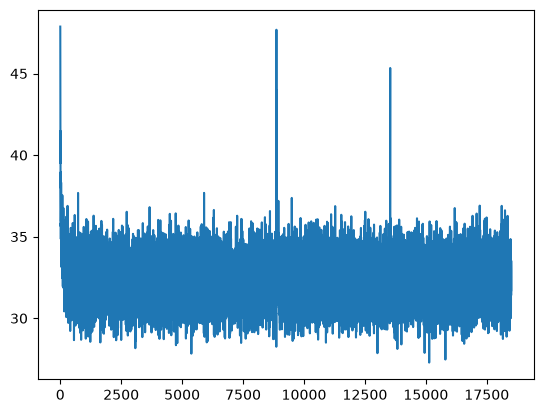

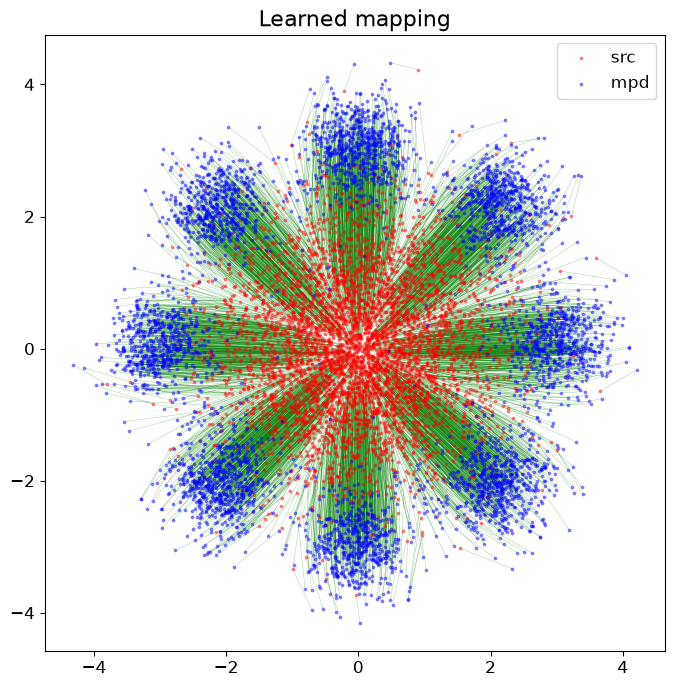

 62%|████████████████████████████████████▏                     | 18725/30000 [1:05:57<39:42,  4.73it/s, inv_frac=0.93, loss=-4.08e+4, tloss=3.37e+4]


Spike at iteration 18725 (1042.3× baseline). Capped loss 33702.26, refined loss 45.11.
Diagnostics saved in ./gau_v2cpf_cap10_spike/spikes/iter_018725
Checkpoint saved at iteration 18726: ./gau_v2cpf_cap10_spike/ckpt.pt


In [13]:
print('Fitting the eight Gaussians')
if start_iter >= MAX_ITER:
    print(f'Already at iteration {start_iter} >= MAX_ITER={MAX_ITER}; raise MAX_ITER to continue training.')

try:
    with tqdm(range(start_iter, MAX_ITER)) as tbar:
        for iteration in tbar:
            t_iter = time.perf_counter()
            X = source_sampler.sample(BATCH_SIZE).to(DEVICE)
            Y = target_sampler.sample(BATCH_SIZE).to(DEVICE)
            t = (torch.rand(BATCH_SIZE) + 1e-8).to(DEVICE)

            current_metrics = dict()
            loss, true_loss, batch = measured_ofm_loss(
                model, X, Y, t,
                TorchlbfgsInvParams(lbfgs_params=dict(tolerance_grad=INV_TOLERANCE),
                                    max_iter=INV_MAX_ITER, record_steps=True),
                current_metrics,
            )
            started = time.perf_counter()
            inv_stats = current_metrics['inverse']
            current_metrics.update(loss=loss.item(), true_loss=true_loss.item(),
                                   inv_norms_max=inv_stats['norms_max'])
            baseline, ratio, baseline_rows, is_spike = spike_status(current_metrics['true_loss'])
            diagnostics = batch_components(batch)
            diagnostics.update(spike_baseline=baseline, spike_ratio=ratio, spike=is_spike)
            event = None
            if is_spike:
                event = capture_spike(iteration, batch, model, current_metrics | diagnostics,
                                      baseline_rows, inv_stats)
            diagnostics['t_spike_diag'] = time.perf_counter() - started

            optim.zero_grad()
            loss.backward()
            optim.step(); model.convexify();

            ema(model)

            # profiling: time spent in the inner inverse solve vs. the rest (the time of the
            # per-step diagnostics, t_diag, is excluded from t_total and t_inverse)
            t_diag = inv_stats['time_diag']
            pad = lambda a: np.concatenate([a, np.full(INV_MAX_ITER + 1 - len(a), np.nan)])
            ss = inv_stats['step_stats']
            conv['max_abs'].append(pad(ss[:, 0]))
            conv['norm_max'].append(pad(ss[:, 1]))
            conv['norm_mean'].append(pad(ss[:, 2]))
            conv['n_iter'].append(pad(np.asarray(inv_stats['step_n_iter'], dtype=float)))
            conv['func_evals'].append(pad(np.asarray(inv_stats['step_func_evals'], dtype=float)))
            hist['loss'].append(current_metrics['loss'])
            hist['true_loss'].append(current_metrics['true_loss'])
            hist['t_inverse'].append(current_metrics['times']['inverse'] - t_diag)
            hist['t_ihv'].append(current_metrics['times']['ihv'])
            hist['inv_steps'].append(current_metrics['inverse'].get('steps', float('nan')))
            hist['inv_norms_max'].append(current_metrics['inverse'].get('norms_max', float('nan')))
            hist['t_min'].append(t.min().item())
            hist['t_diag'].append(t_diag)
            for key, value in diagnostics.items():
                hist[key].append(value)
            hist['t_total'].append(time.perf_counter() - t_iter - t_diag - diagnostics['t_spike_diag'])

            tbar.set_postfix(loss=current_metrics['loss'], tloss = current_metrics['true_loss'],
                             inv_frac=np.mean(hist['t_inverse'][-100:]) / np.mean(hist['t_total'][-100:]))
            if iteration % 500 == 0 or iteration == MAX_ITER - 1:
                clear_output(wait=True)
                print("Iteration", iteration)
                print(f'\nLoss: {true_loss.item()}')
                avg = lambda k: 1e3 * np.mean(hist[k][-500:])
                print(f"Profile (avg last 500 iters): total {avg('t_total'):.1f} ms | inverse {avg('t_inverse'):.1f} ms "
                      f"({100*avg('t_inverse')/avg('t_total'):.0f}%) | ihv {avg('t_ihv'):.1f} ms | "
                      f"L-BFGS steps {np.mean(hist['inv_steps'][-500:]):.1f} | cap hit {100*np.mean(np.asarray(hist['inv_steps'][-500:]) >= INV_MAX_ITER):.0f}%")
                plt.plot(hist['true_loss'])
                plt.savefig(loss_path)
                plt.show()
                X = source_sampler.sample(5000).to(DEVICE)
                Y = model.push_nograd(X)
                visualize_2d_map(
                    X.cpu().numpy(),
                    Y.cpu().numpy(),
                    'Learned mapping',
                    data_label='src', mapped_data_label='mpd', s=3, figsize=(8, 8), save_path=samples_path)
            if event is not None:
                event_dir, summary = event
                print(f"Spike at iteration {iteration} ({ratio:.1f}× baseline). "
                      f"Capped loss {summary['capped_true_loss']:.2f}, "
                      f"refined loss {summary['refined_true_loss']:.2f}.")
                print(f'Diagnostics saved in {event_dir}')
                if STOP_ON_SPIKE:
                    break
            if (iteration + 1) % CKPT_EVERY == 0:
                save_checkpoint()
except KeyboardInterrupt:
    print('Interrupted; saving checkpoint')

if len(hist['loss']) > start_iter:
    save_checkpoint()
    print(f"Checkpoint saved at iteration {len(hist['loss'])}: {CKPT_PATH}")
